Best = good housing condition relative to assessed value.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
df = pd.read_csv("data.csv" , low_memory=False)
cent = pd.read_csv("cent.csv" , low_memory=False)
df.shape, cent.shape

((584995, 86), (583956, 77))

In [24]:
nb = cent[["PIN", "geo_name_n"]].rename(columns={"PIN": "PARID", "geo_name_n": "NEIGHBORHOOD"})
nb["NEIGHBORHOOD"] = nb["NEIGHBORHOOD"].str.strip()
nb = nb[nb["NEIGHBORHOOD"] != ""]
nb = nb.drop_duplicates(subset="PARID")

d = df[df["CLASSDESC"] == "RESIDENTIAL"].merge(nb, on= "PARID", how="inner")
d = d.dropna(subset=["CONDITIONDESC"])
d = d[d["FAIRMARKETTOTAL"] > 10000]
print(len(d), d["NEIGHBORHOOD"].nunique())

96911 90


In [25]:
houses = ["SINGLE FAMILY", "ROWHOUSE", "TOWNHOUSE", "TWO FAMILY", "THREE FAMILY", "FOUR FAMILY"]
d = d[d["USEDESC"].isin(houses)]
print(len(d), d["NEIGHBORHOOD"].nunique())

92261 90


In [26]:
cond_map = {"EXCELLENT": 1, "VERY GOOD": 2, "GOOD": 3, "AVERAGE": 4,
            "FAIR": 5, "POOR": 6, "VERY POOR": 7, "UNSOUND": 8}
d["condition_num"] = d["CONDITIONDESC"].map(cond_map)
print(d["condition_num"].isna().sum())     # should print 0
d["quality"] = 9 - d["condition_num"]      # higher = better

0


In [27]:
g = (d.groupby("NEIGHBORHOOD")
       .agg(median_value=("FAIRMARKETTOTAL", "median"),
            avg_quality=("quality", "mean"),
            n_homes=("PARID", "count"))
       .query("n_homes >= 30")
       .reset_index())
print(g.shape)
g.sort_values("avg_quality", ascending=False).head(10)

(84, 4)


,NEIGHBORHOOD,median_value,avg_quality,n_homes
73,Strip District,262300.0,5.720000,100
69,Squirrel Hill North,360000.0,5.562089,2279
62,Shadyside,330300.0,5.436712,1983
4,Banksville,110550.0,5.309801,1204
57,Point Breeze,250650.0,5.256552,1984
0,Allegheny West,223900.0,5.247863,117
60,Regent Square,210650.0,5.184783,368
52,North Oakland,250300.0,5.131455,213
70,Squirrel Hill South,217700.0,5.078352,3714
16,Central Northside,135000.0,5.039753,1132


In [28]:
s = (d.groupby("NEIGHBORHOOD")
       .agg(median_value=("FAIRMARKETTOTAL", "median"),
            avg_quality=("quality", "mean"),
            n_homes=("PARID", "count"))
         .query("n_homes >= 30")
         .reset_index())
print(s.shape)

(84, 4)


In [29]:
s["log_value"] = np.log(s["median_value"])
s["z_quality"] = (s["avg_quality"] - s["avg_quality"].mean()) / s["avg_quality"].std()
s["z_value"] = (s["log_value"] - s["log_value"].mean()) / s["log_value"].std()

w_quality = 0.5
raw = w_quality * s["z_quality"] + (1 - w_quality) * s["z_value"]
s["housing_score"] = 100 * (raw - raw.min()) / (raw.max() - raw.min())

s = s.sort_values("housing_score", ascending=False).reset_index(drop=True)
s[["NEIGHBORHOOD", "housing_score", "median_value", "avg_quality", "n_homes"]].head(10)


,NEIGHBORHOOD,housing_score,median_value,avg_quality,n_homes
0,Squirrel Hill North,100.000000,360000.0,5.562089,2279
1,Strip District,99.436396,262300.0,5.720000,100
2,Shadyside,94.068213,330300.0,5.436712,1983
3,Point Breeze,82.667249,250650.0,5.256552,1984
4,Allegheny West,80.235660,223900.0,5.247863,117
5,North Oakland,78.346193,250300.0,5.131455,213
6,Regent Square,76.916996,210650.0,5.184783,368
7,Squirrel Hill South,73.885453,217700.0,5.078352,3714
8,Banksville,69.021995,110550.0,5.309801,1204
9,Friendship,66.778535,198050.0,4.923423,222


In [30]:
counts = Counter()
weights = np.arange(0, .95, 0.05)
for wq in weights:
    tmp = wq * s["z_quality"] + (1 - wq) * s["z_value"]
    for name in s.loc[tmp.sort_values(ascending=False).index[:3], "NEIGHBORHOOD"]:
        counts[name] += 1

robust = pd.Series(counts).sort_values(ascending=False)
print(len(weights), "weightings tested")
robust.head(8)

19 weightings tested


Squirrel Hill North    19
Shadyside              19
Strip District         19
dtype: int64

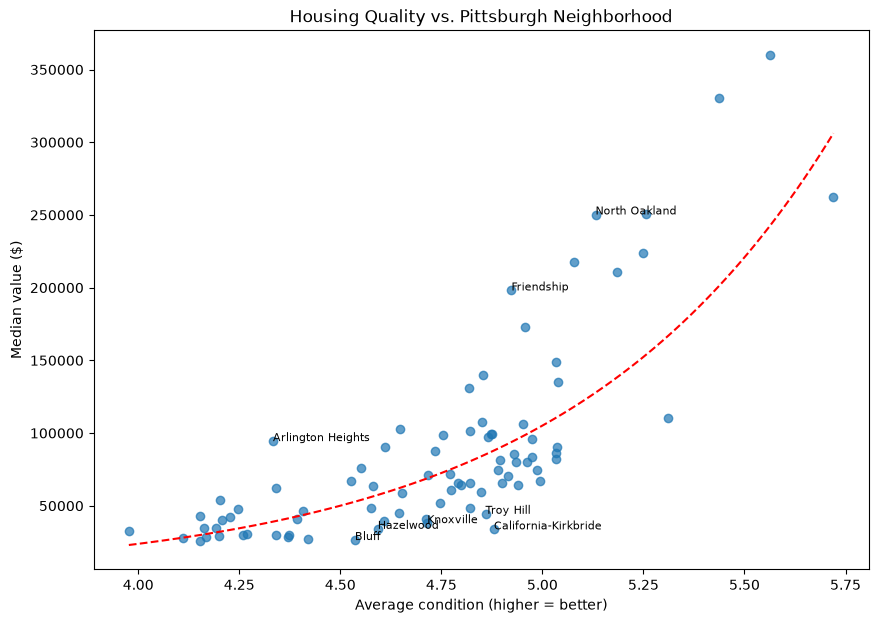

In [31]:
x, y = s["avg_quality"], s["log_value"]
solpe, intercept = np.polyfit(x, y, 1)
s["residual"] = y - (solpe * x + intercept)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(x, s["median_value"], alpha=0.7)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, np.exp(solpe * xs + intercept), color="red", linestyle="--", label="Regression line")
for _, r in pd.concat([s.nsmallest(5, "residual"), s.nlargest(3, "residual")]).iterrows():
    ax.annotate(r["NEIGHBORHOOD"], (r["avg_quality"], r["median_value"]), fontsize=8)
ax.set_xlabel("Average condition (higher = better)")
ax.set_ylabel("Median value ($)")
ax.set_title("Housing Quality vs. Pittsburgh Neighborhood")
plt.show()

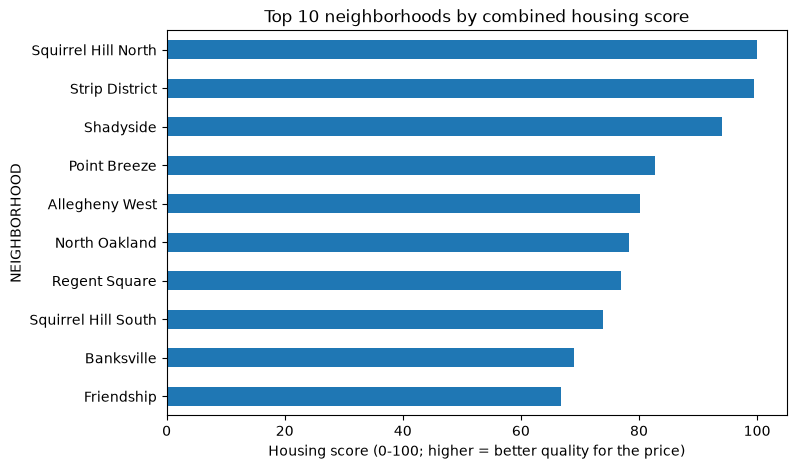

In [32]:
top = s.head(10).sort_values("housing_score")
top.plot.barh(x="NEIGHBORHOOD", y="housing_score", figsize=(8, 5), legend=False)
plt.xlabel("Housing score (0-100; higher = better quality for the price)")
plt.title("Top 10 neighborhoods by combined housing score")
plt.show()                         

In [33]:
for name in s["NEIGHBORHOOD"].head(3):
    sub = d[d["NEIGHBORHOOD"] == name]
    print(name, len(sub))
    print(sub["FAIRMARKETTOTAL"].describe()[["min", "50%", "max"]].to_string())
    print(sub["CONDITIONDESC"].value_counts().to_string())
    print()

Squirrel Hill North 2279
min      21900.0
50%     360000.0
max    3090000.0
CONDITIONDESC
AVERAGE      1188
GOOD          731
VERY GOOD     250
FAIR           65
EXCELLENT      41
POOR            4

Strip District 100
min     11900.0
50%    262300.0
max    841400.0
CONDITIONDESC
VERY GOOD    46
AVERAGE      23
FAIR         15
GOOD         11
UNSOUND       2
VERY POOR     2
POOR          1

Shadyside 1983
min      60000.0
50%     330300.0
max    2284400.0
CONDITIONDESC
AVERAGE      975
GOOD         718
VERY GOOD    135
FAIR         134
EXCELLENT     11
POOR           9
VERY POOR      1



In [34]:
s[["NEIGHBORHOOD", "housing_score"]].to_csv("housing_by_neighborhood.csv", index=False)